RL for logistics Center V2

In [2]:
# Defining an enviroment for the agent (logistics center)
import numpy as np
import random as rd
import copy as cp

# The logistics center is created according to the docks number and SKU numbers
# SKU number = the different number of products avaible in the warehouse
# docker number = the different number of docks in the warehouse
class logistics_center:

    def __init__(self, num_docks = 3, num_SKU = 3, num_deliveries = 4):
        self.num_docks = num_docks
        self.num_SKU = num_SKU
        self.num_deliveries = num_deliveries
        self.my_table = Qtable(lr = 0.02, gamma = 1)

    # the warehouse is a matrix, that contains zeros as "empty space", ones which are the docks, and twos, which are the the SKU positions
    def create_warehouse(self):

        warehouse = np.zeros((self.num_docks, (self.num_docks + 2)))

        for i in range(self.num_docks):
            warehouse[i,0] = 1

        j = 0 

        while j < self.num_SKU:
            a , b = rd.randint(0, (self.num_docks -1)), rd.randint(1, (self.num_docks + 1))
            if warehouse[a,b] == 0:
                warehouse[a, b] = 2
                j += 1

        return warehouse

    # This function is responsible for reseting the enviroment for a new episode to start
    def reset(self):
        self.warehouse = self.create_warehouse()
        self.state = State(self.warehouse, self.num_deliveries)
        self.agent = Agent(self.warehouse, self.state)

    def reward(self):
        if self.agent.invalid_delivery:
            return -20

        delivery = self.agent.current_chosen_delivery

        if self.state.current_episode_time <= self.state.deadline[delivery]:
            return 20

        else:
            return -50


    #here is where we define the episode
    def episode(self):
        self.reset()
        p_state = cp.deepcopy(self.state)
        actions_list =[self.agent.pick_delivery1, self.agent.pick_delivery2, self.agent.pick_delivery3, self.agent.pick_delivery4]
        b = 0
        total_reward_per_episode = 0
        
        while True:
            done = False
            a = self.my_table.choose_action(state=self.state)
            actions_list[a]()
    
            if self.agent.invalid_delivery:
                reward = self.reward()
                total_reward_per_episode += reward

                self.my_table.update_q_table(
                    state=p_state,
                    action=a,
                    reward=reward,
                    next_state=self.state,
                    done=done
                )

                p_state = cp.deepcopy(self.state)

                print("Invalid delivery")
                print("Reward:", reward)

                continue
            
            agent_position = self.state.position
            sku_position = self.state.pick_SKUs[self.agent.current_chosen_delivery]
            dock_position = self.state.delivery_docks[self.agent.current_chosen_delivery]
            distance_a_to_sku = abs(agent_position[0] - sku_position[0]) + abs(agent_position[1] - sku_position[1])
            distance_sku_to_dd = abs(sku_position[0] - dock_position[0]) + abs(sku_position[1] - dock_position[1])
            total_distance = distance_a_to_sku + distance_sku_to_dd
            time = self.state.current_episode_time + total_distance

            if time <= self.state.deadline[self.agent.current_chosen_delivery]:
                b += 1 
                self.state.current_episode_time = time
                self.state.status[self.agent.current_chosen_delivery] = 0
                self.state.position = [int(x) for x in dock_position]
                print(f"Delivery on time: {b}")

            else:
                self.state.current_episode_time = time
                self.state.status[self.agent.current_chosen_delivery] = 0
                self.state.position = [int(x) for x in dock_position]
                print(f"Delivery out of time")

            reward = self.reward()

            if np.array_equal(self.state.status, np.array([0, 0, 0, 0])):
                print("All deliveries were done")
                done = True

            self.my_table.update_q_table(
                state=p_state,
                action=a,
                reward=reward,
                next_state=self.state,
                done=done
            )

            total_reward_per_episode += reward
            
            if done:
                self.my_table.epsilon = max(self.my_table.epsilon*self.my_table.epsilon_decay, self.my_table.epsilon_min)
                break

            p_state = cp.deepcopy(self.state)
            
            print("Position:", self.state.position)
            print("Reward:", reward)
            print("Epsilon:", self.my_table.epsilon)
        return total_reward_per_episode, b

In [3]:
import itertools


class State:

    def __init__(self, warehouse_created, num_deliveries):

        self.num_deliveries = num_deliveries

        # Posições vazias para o agente começar
        empty_positions = np.argwhere(
            warehouse_created == 0
        )

        self.position = empty_positions[
            np.random.randint(len(empty_positions))
        ].copy()

        # Posições dos SKUs
        sku_positions = np.argwhere(
            warehouse_created == 2
        )

        # Posições das docas
        dock_positions = np.argwhere(
            warehouse_created == 1
        )

        # Sorteia os SKUs das entregas
        self.pick_SKUs = np.array([
            sku_positions[
                np.random.randint(len(sku_positions))
            ].copy()
            for _ in range(num_deliveries)
        ])

        # Sorteia as docas das entregas
        self.delivery_docks = np.array([
            dock_positions[
                np.random.randint(len(dock_positions))
            ].copy()
            for _ in range(num_deliveries)
        ])

        # 1 = entrega ainda disponível
        # 0 = entrega concluída
        self.status = np.ones(
            num_deliveries,
            dtype=int
        )

        # Tempo atual do episódio
        self.current_episode_time = 0

        # Cria deadlines factíveis
        self.deadline = self.generate_deadlines()

    def calculate_delivery_time(self, delivery):

        # Agente -> SKU
        agent_to_sku = np.sum(
            np.abs(
                self.position -
                self.pick_SKUs[delivery]
            )
        )

        # SKU -> doca
        sku_to_dock = np.sum(
            np.abs(
                self.pick_SKUs[delivery] -
                self.delivery_docks[delivery]
            )
        )

        return agent_to_sku + sku_to_dock

    def generate_deadlines(self):

        # Testa as 24 ordens possíveis
        for order in itertools.permutations(
            range(self.num_deliveries)
        ):

            current_position = self.position.copy()
            current_time = 0

            deadlines = np.zeros(
                self.num_deliveries,
                dtype=int
            )

            for delivery in order:

                # Posição atual -> SKU
                time_to_sku = np.sum(
                    np.abs(
                        current_position -
                        self.pick_SKUs[delivery]
                    )
                )

                # SKU -> doca
                time_to_dock = np.sum(
                    np.abs(
                        self.pick_SKUs[delivery] -
                        self.delivery_docks[delivery]
                    )
                )

                # Tempo dessa entrega
                delivery_time = (
                    time_to_sku +
                    time_to_dock
                )

                # Tempo acumulado
                current_time += delivery_time

                # Deadline da entrega
                deadlines[delivery] = current_time

                # Depois da entrega, o agente está na doca
                current_position = (
                    self.delivery_docks[delivery].copy()
                )

            # Essa ordem é sempre factível,
            # pois os deadlines foram construídos
            # exatamente com base nela.
            return deadlines

        raise ValueError(
            "Não foi possível gerar os deadlines."
        )

In [4]:
# defining the agent, which is going to have actions and get the state and warehouse created
# the agent can move upwards, downwards and go to the left or to the right, movimentation implemented via matrix 
# we also change the state here, by moving the agent, the dealine is changed as well as the has_SKU state

class Agent():

    def __init__(self, warehouse_created, state):

        self.warehouse_created = warehouse_created
        self.state = state 
        self.invalid_delivery = False

    def pick_delivery1(self):
        self.invalid_delivery = False

        if self.state.status[0] == 1:
            self.current_chosen_delivery = 0
            self.SKU_requisition = self.state.pick_SKUs[0]
            self.delivery_dock = self.state.delivery_docks[0]
            return 0

        self.invalid_delivery = True
        return None


    def pick_delivery2(self):
        self.invalid_delivery = False

        if self.state.status[1] == 1:
            self.current_chosen_delivery = 1
            self.SKU_requisition = self.state.pick_SKUs[1]
            self.delivery_dock = self.state.delivery_docks[1]
            return 1

        self.invalid_delivery = True
        return None

    def pick_delivery3(self):
        self.invalid_delivery = False

        if self.state.status[2] == 1:
            self.current_chosen_delivery = 2
            self.SKU_requisition = self.state.pick_SKUs[2]
            self.delivery_dock = self.state.delivery_docks[2]
            return 2

        self.invalid_delivery = True
        return None
    
    def pick_delivery4(self):
        self.invalid_delivery = False

        if self.state.status[3] == 1:
            self.current_chosen_delivery = 3
            self.SKU_requisition = self.state.pick_SKUs[3]
            self.delivery_dock = self.state.delivery_docks[3]
            return 3

        self.invalid_delivery = True
        return None

In [5]:
# the first model we will try it's gonna be Q-Learning

class Qtable():

    def __init__(self, lr, gamma, epsilon=1.0, epsilon_decay=0.995, epsilon_min=0.01):
        self.lr = lr
        self.gamma = gamma

        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min

        self.q_table = {}

    def get_q_values(self, state):

        state_key = self.state_to_key(state)

        if state_key not in self.q_table:
            self.q_table[state_key] = np.zeros(4)

        return self.q_table[state_key]

    def state_to_key(self, state):

        position = tuple(state.position)

        deliveries = tuple(
            (
                tuple(state.pick_SKUs[i]),
                tuple(state.delivery_docks[i]),
                state.deadline[i]
            )
            for i in range(len(state.status))
            if state.status[i] == 1
        )

        current_episode_time = state.current_episode_time

        return (
            position,
            deliveries,
            current_episode_time
        )

    def choose_action(self, state):

        q_values = self.get_q_values(state)

        possible_actions = []

        for i in range(len(state.status)):
            if state.status[i] == 1:
                possible_actions.append(i)

        # Exploração
        if np.random.rand() < self.epsilon:
            action = np.random.choice(possible_actions)

        # Aproveitamento
        else:
            possible_q_values = q_values[possible_actions]
            action = possible_actions[np.argmax(possible_q_values)]

        return action

    def update_q_table(self, state, action, reward, next_state, done):

        current_q_values = self.get_q_values(state)
        next_q_values = self.get_q_values(next_state)

        current_q = current_q_values[action]

        if done:

            target = reward

        else:

            possible_next_actions = []

            for i in range(len(next_state.status)):
                if next_state.status[i] == 1:
                    possible_next_actions.append(i)

            if possible_next_actions:
                max_next_q = np.max(next_q_values[possible_next_actions])
            else:
                max_next_q = 0

            target = reward + self.gamma * max_next_q

        self.q_table[self.state_to_key(state)][action] = (
            current_q + self.lr * (target - current_q)
        )

In [6]:
env = logistics_center()
rewards_list = []
deliveries_on_time_list = []
env.my_table.epsilon_decay = 0.999

for episode in range(7000):
    print(f"\n--- Episode {episode + 1} ---")
    a, b = env.episode()
    rewards_list.append(a)
    deliveries_on_time_list.append(b)



--- Episode 1 ---
Delivery on time: 1
Position: [0, 0]
Reward: 20
Epsilon: 1.0
Delivery out of time
Position: [1, 0]
Reward: -50
Epsilon: 1.0
Delivery out of time
Position: [2, 0]
Reward: -50
Epsilon: 1.0
Delivery out of time
All deliveries were done

--- Episode 2 ---
Delivery on time: 1
Position: [2, 0]
Reward: 20
Epsilon: 0.999
Delivery on time: 2
Position: [1, 0]
Reward: 20
Epsilon: 0.999
Delivery on time: 3
Position: [0, 0]
Reward: 20
Epsilon: 0.999
Delivery out of time
All deliveries were done

--- Episode 3 ---
Delivery on time: 1
Position: [1, 0]
Reward: 20
Epsilon: 0.998001
Delivery on time: 2
Position: [0, 0]
Reward: 20
Epsilon: 0.998001
Delivery out of time
Position: [1, 0]
Reward: -50
Epsilon: 0.998001
Delivery out of time
All deliveries were done

--- Episode 4 ---
Delivery on time: 1
Position: [1, 0]
Reward: 20
Epsilon: 0.997002999
Delivery on time: 2
Position: [2, 0]
Reward: 20
Epsilon: 0.997002999
Delivery on time: 3
Position: [1, 0]
Reward: 20
Epsilon: 0.997002999
Del

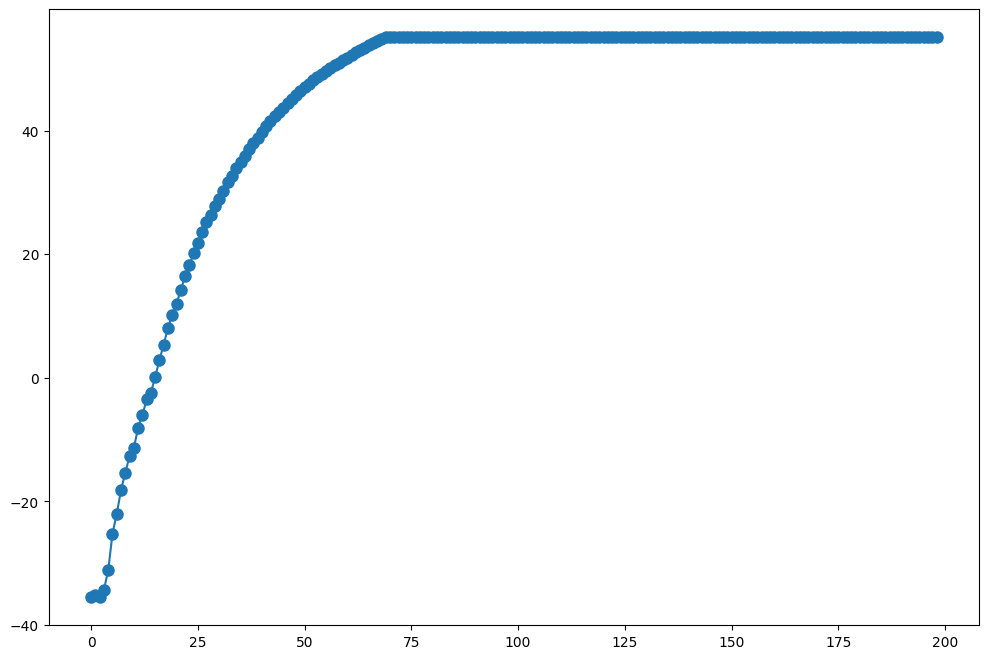

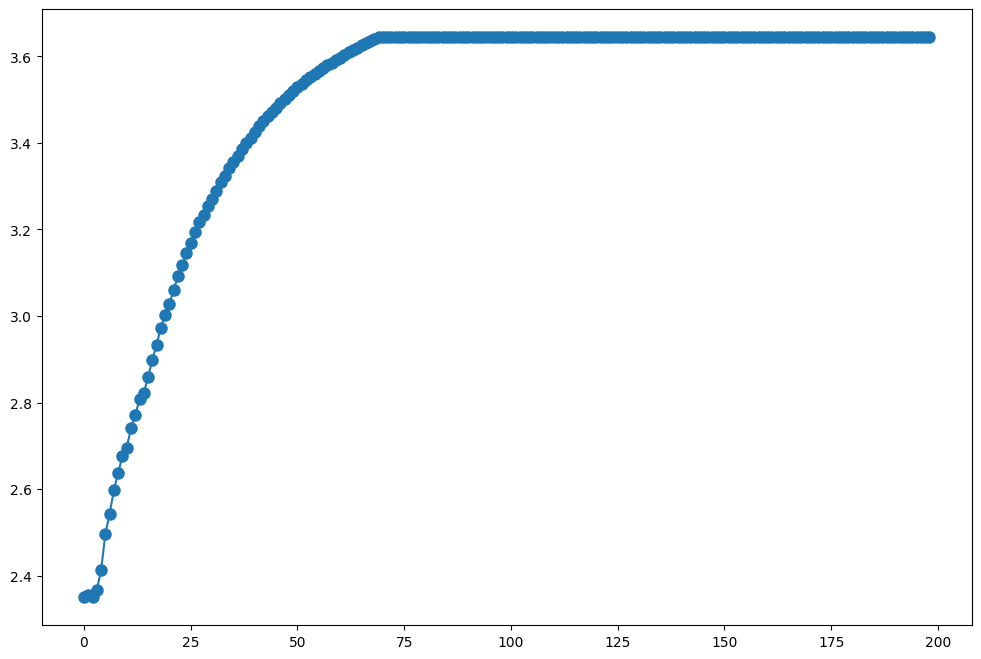

In [7]:
import matplotlib.pyplot as plt

mean_rewards = []
mean_deliveries = []
for i in range(100, 20000, 100):
    mean_reward = sum(rewards_list[:i])/len(rewards_list[:i])
    mean_deliverie = sum(deliveries_on_time_list[:i])/len(deliveries_on_time_list[:i])
    mean_rewards.append(mean_reward)
    mean_deliveries.append(mean_deliverie)


plt.figure(figsize=(12,8))
plt.plot(range(len(mean_rewards)), mean_rewards, marker = 'o', markersize = 8)
plt.figure(figsize=(12,8))
plt.plot(range(len(mean_deliveries)), mean_deliveries, marker = 'o', markersize = 8)

Now, the ideia is to upgrade the model, with a more complex problem so we are going to make some changes at the original logistics center


In [8]:
from collections import deque

# =============================================================================
# logistics_center2: the ENVIRONMENT.
# It models a warehouse where a central dispatcher (the RL agent) decides which
# delivery each operator should do next. This class holds:
#   - the warehouse layout and the path-distance computation,
#   - the Q-table (self.my_table) used by the dispatcher,
#   - the training / evaluation loop (episode / evaluate).
# Per-episode data (positions, deadlines, corridor windows...) lives in State2,
# and the delivery execution lives in Agent2; both are recreated in reset().
# =============================================================================
class logistics_center2:

    def __init__(self, num_docks=10, num_SKU=4, num_deliveries=20,
                 top_k=5, lr=0.1, gamma=0.95,
                 epsilon=1.0, epsilon_decay=0.998, epsilon_min=0.01, num_operators = 4):
        # --- Environment settings ---
        self.num_operators = num_operators    # operators working in parallel
        self.num_docks = num_docks            # also used as the warehouse size (matrix is num_docks x num_docks)
        self.num_SKU = num_SKU                # number of shelf rows (corridors = num_SKU + 1)
        self.num_deliveries = num_deliveries  # deliveries to complete in each episode
        self.top_k = top_k                    # how many candidate deliveries the agent can choose from
        self.block_penalty = 15               # extra penalty when a route has to wait for a busy corridor
        self.warehouse = self.create_warehouse()   # fixed layout, built once
        self._dist_cache = {}                 # cache of path distances (the layout never changes)

        # --- The learning part: a Q-table with its hyperparameters ---
        # lr = learning rate, gamma = discount factor, epsilon = exploration rate (decays over episodes)
        self.my_table = Qtable2(lr=lr, gamma=gamma, top_k=top_k,
                                epsilon=epsilon, epsilon_decay=epsilon_decay,
                                epsilon_min=epsilon_min)

    # 0 = empty space, 1 = docks, 2 = SKU positions (shelfs)
    # Builds the grid: docks form an "L" (left column and top row) and the shelves
    # (SKU cells) are horizontal blocks on rows 2, 4, 6, 8, leaving free corridors between them.
    def create_warehouse(self):
        warehouse = np.zeros((self.num_docks, self.num_docks))
        for i in range(self.num_docks):
            if i < 5:
                warehouse[i, 0] = 1
            else:
                warehouse[0, i - 4] = 1
        for j in range(2, self.num_SKU * 2 + 1, 2):
            warehouse[j, 2:8] = 2
        return warehouse

    # Best trajectory (BFS and don't go over the shelfs). Result in cache.
    # Public entry point for distances: converts positions to tuples, looks the pair up
    # in the cache, and only runs the BFS the first time that pair is requested.
    def shortest_path_distance(self, start, target):
        start = (int(start[0]), int(start[1]))
        target = (int(target[0]), int(target[1]))

        key = (start, target)
        if key in self._dist_cache:
            return self._dist_cache[key]

        distance = self._bfs(start, target)
        self._dist_cache[key] = distance
        return distance

    # Breadth-first search over the grid (4 directions, 1 step = 1 time unit).
    # Shelf cells (value 2) cannot be crossed, but they CAN be the destination,
    # because the operator must reach a shelf cell to pick the SKU.
    # Returns None if the target is unreachable.
    def _bfs(self, start, target):
        if start == target:
            return 0

        movements = [(-1, 0), (1, 0), (0, -1), (0, 1)]   # up, down, left, right
        queue = deque([(start, 0)])                      # (cell, distance so far)
        visited = {start}

        while queue:
            (row, col), distance = queue.popleft()

            for d_row, d_col in movements:
                nxt = (row + d_row, col + d_col)

                # ignore cells outside the grid
                if not (0 <= nxt[0] < self.warehouse.shape[0]
                        and 0 <= nxt[1] < self.warehouse.shape[1]):
                    continue
                # ignore cells already explored
                if nxt in visited:
                    continue
                if nxt == target:               
                    return distance + 1
                if self.warehouse[nxt] == 2:    # can't go trough other SKUs
                    continue

                visited.add(nxt)
                queue.append((nxt, distance + 1))

        return None

    # Prepara um novo episódio
    # Creates a fresh random problem: State2 draws operator positions, the SKUs and dock of each
    # delivery, and generates feasible deadlines; Agent2 is the object that executes deliveries on it.
    def reset(self):
        self.state = State2(self.warehouse, self.num_deliveries, self, self.top_k, num_operators = self.num_operators)
        self.agent = Agent2(self.warehouse, self.state)

    # Reward for ONE delivery: +20 if on time, -50 if late.
    # If the operator had to wait for a busy corridor, an extra penalty is subtracted.
    def reward(self, on_time, blocked):
        r = 20 if on_time else -50
        if blocked:
            r -= self.block_penalty      
        return r

    # Runs ONE full episode (all deliveries done). train=True learns and explores (epsilon-greedy);
    # train=False always picks the best known action and does not update anything.
    # Each loop iteration is ONE dispatch decision: the operator who becomes free first asks
    # for his next delivery (event-driven time, there is no global clock).
    def episode(self, train=True):
        self.reset()
        state, agent, table = self.state, self.agent, self.my_table

        # per-episode metrics
        on_time_count = 0
        blocked_count = 0
        total_reward = 0

        # first decision: the operator with the smallest free_at (all start at 0)
        # cands = candidate deliveries; obs = the discretized state the Q-table sees
        operator = state.next_operator()
        cands, obs = state.observation(operator)

        while True:
            # the agent picks a RANK among the candidates (0 = most urgent one);
            # greedy=True (evaluation) disables exploration
            action = table.choose_action(obs, len(cands), greedy=not train)
            # translate the rank into the real delivery index
            delivery = agent.pick_delivery(action, cands)

            # execute the delivery: the route is simulated (waiting for busy corridors if needed)
            # and it returns whether it was on time and whether it was blocked
            on_time, blocked = agent.execute_delivery(delivery, operator)   
            reward = self.reward(on_time, blocked)                          

            on_time_count += on_time
            blocked_count += blocked                                        
            total_reward += reward
            done = not state.status.any()    # episode ends when no delivery is pending

            # Next state: seen from the NEXT operator to become free (it may be a different one).
            if done:
                next_cands, next_obs = [], None
            else:
                operator = state.next_operator()
                next_cands, next_obs = state.observation(operator)

            # Q-learning update for the decision that was just made:
            # Q(obs, action) moves toward reward + gamma * best Q of the next state
            if train:
                table.update_q_table(obs, action, reward, next_obs, len(next_cands), done)

            if done:
                break
            # the next state becomes the current one for the following iteration
            cands, obs = next_cands, next_obs
        # exploration decays once per episode (training only)
        if train: 
            table.decay_epsilon()
        return total_reward, on_time_count, blocked_count

    # Average number of on-time deliveries over n_episodes using the greedy policy
    # (no exploration, no learning). Every episode is a new random problem.
    def evaluate(self, n_episodes=500):
        return float(np.mean([self.episode(train=False)[1] for _ in range(n_episodes)]))

In [9]:
import itertools

class State2:
    # State2 holds everything that exists in ONE episode (one "work day"):
    # operators, deliveries, deadlines, corridor occupation, and which deliveries are done.
    # It also knows how to simulate routes and how to build the observation the agent sees.

    # Slack (deadline - estimated finish time) is converted to a bin number using these limits:
    # bin 0: slack < 0 | bin 1: 0-3 | bin 2: 4-9 | bin 3: 10-19 | bin 4: >= 20
    SLACK_BINS = [0, 4, 10, 20]

    def __init__(self, warehouse_created, num_deliveries, environment,
                 top_k=3, deadline_slack=1, num_operators=1, num_SKUs_per_delivery=3):
        self.num_deliveries = num_deliveries
        self.warehouse_created = warehouse_created
        self.environment = environment              # used to compute shortest-path distances
        self.top_k = top_k                          # how many candidate deliveries the agent chooses from
        self.deadline_slack = deadline_slack        # multiplier applied to the deadlines (1 = exact plan)
        self.num_operators = num_operators
        self.num_SKUs_per_delivery = num_SKUs_per_delivery

        # Random starting position for each operator: distinct empty cells of the warehouse
        empty_positions = np.argwhere(warehouse_created == 0)
        chosen = np.random.choice(len(empty_positions), size=num_operators, replace=False)
        self.positions = empty_positions[chosen].copy()

        # Time at which each operator becomes free (all start at time 0)
        self.free_at = np.zeros(num_operators, dtype=int)

        # One list per corridor; each item will be a (start, end) time interval in which
        # that corridor is occupied by some operator
        self.busy_windows = [[] for _ in range(self.environment.num_SKU + 1)]

        sku_positions = np.argwhere(warehouse_created == 2)
        dock_positions = np.argwhere(warehouse_created == 1)

        # pick_SKUs has shape (num_deliveries, num_SKUs_per_delivery, 2):
        # the (row, col) of each SKU of each delivery. SKUs are distinct inside a delivery.
        self.pick_SKUs = np.array([
            sku_positions[np.random.choice(len(sku_positions),
                                           size=num_SKUs_per_delivery,
                                           replace=False)].copy()
            for _ in range(num_deliveries)
        ])

        # One corridor per SKU, shape (num_deliveries, num_SKUs_per_delivery).
        # A shelf at row r touches corridors (r-1)//2 and (r-1)//2 + 1; one of them is drawn randomly.
        self.delivery_corridor = ((self.pick_SKUs[:, :, 0] - 1) // 2
                                  + np.random.randint(0, 2, size=(num_deliveries, num_SKUs_per_delivery)))

        # Dock where each delivery must be dropped off
        self.delivery_docks = np.array([
            dock_positions[np.random.randint(len(dock_positions))].copy()
            for _ in range(num_deliveries)
        ])

        # 1 = delivery pending, 0 = delivery completed
        self.status = np.ones(num_deliveries, dtype=int)

        # Deadlines are always feasible: they come from a real plan (see generate_deadlines)
        self.deadline = self.generate_deadlines()

    # Simulates one operator doing one delivery, WITHOUT changing the state.
    # Inputs: the delivery, where the operator starts, at what time, and the corridor windows to respect.
    # Returns: (finish time, whether the operator had to wait, new windows created, visiting order).
    def simulate_route(self, delivery, start, start_time, windows):
        dist = self.environment.shortest_path_distance
        skus = self.pick_SKUs[delivery]
        dock = self.delivery_docks[delivery]
        corridors = self.delivery_corridor[delivery]

        best = None

        # Try every possible order of visiting the SKUs (3 SKUs -> 6 orders)
        for order in itertools.permutations(range(self.num_SKUs_per_delivery)):
            time = start_time
            position = start
            waited = False
            new_windows = []
            valid = True

            for k in order:
                # Travel time from the current position to the next SKU
                travel = dist(position, skus[k])
                if travel is None:
                    valid = False
                    break

                corridor = int(corridors[k])

                # While the trip would overlap an existing window of this corridor,
                # wait until that window ends and check again.
                # Overlap rule: new starts before the existing ends AND new ends after the existing starts.
                while True:
                    conflicts = [end for (begin, end) in windows[corridor]
                                 if time < end and time + travel > begin]
                    if not conflicts:
                        break
                    time = max(conflicts)
                    waited = True

                # The corridor is occupied from the moment the operator leaves until the item is picked.
                # The window is only stored locally here, so two SKUs of the same delivery
                # in the same corridor do not block each other.
                new_windows.append((corridor, time, time + travel))
                time += travel
                position = skus[k]

            if not valid:
                continue

            # Last leg: from the last SKU to the dock (this leg blocks nothing)
            to_dock = dist(position, dock)
            if to_dock is None:
                continue
            time += to_dock

            # Keep the order with the earliest finish; on ties, prefer the one without waiting
            key = (time, waited)
            if best is None or key < best[0]:
                best = (key, order, new_windows)

        if best is None:
            return None, None, None, None

        (finish, waited), order, new_windows = best
        return finish, waited, new_windows, order

    # Builds one deadline per delivery from a real plan, so deadlines are always achievable.
    def generate_deadlines(self):
        # Random order in which deliveries will be "assigned" in the plan
        order = np.random.permutation(self.num_deliveries)

        # Local copies: the real state is not modified while building the plan
        positions = self.positions.copy()
        free_at = np.zeros(self.num_operators, dtype=int)
        windows = [[] for _ in range(len(self.busy_windows))]
        deadlines = np.zeros(self.num_deliveries, dtype=int)

        for delivery in order:
            # The operator who becomes free first takes the next delivery
            operator = int(np.argmin(free_at))

            finish, waited, new_windows, _ = self.simulate_route(
                delivery, positions[operator], free_at[operator], windows)

            # Unreachable delivery: draw a new plan
            if finish is None:
                return self.generate_deadlines()

            # Record the corridor windows of this plan
            for corridor, begin, end in new_windows:
                windows[corridor].append((begin, end))

            free_at[operator] = finish
            positions[operator] = self.delivery_docks[delivery]
            # The slack multiplier is applied only to the final deadline
            deadlines[delivery] = int(finish * self.deadline_slack)

        return deadlines

    # The next operator to decide is the one who becomes free first
    def next_operator(self):
        return int(np.argmin(self.free_at))

    # Simulates every pending delivery for the given operator, without saving anything.
    # Returns {delivery: (finish time, would wait?)}
    def route_options(self, operator):
        options = {}
        for i in range(self.num_deliveries):
            if self.status[i] == 1:
                finish, waited, _, _ = self.simulate_route(
                    i, self.positions[operator], self.free_at[operator], self.busy_windows)
                options[i] = (finish, waited)
        return options

    # Picks the top_k candidates: deliveries WITHOUT waiting come first (by earliest deadline);
    # deliveries WITH waiting only fill the remaining slots.
    def select_candidates(self, options):
        pending = sorted(options, key=lambda i: self.deadline[i])
        free = [i for i in pending if not options[i][1]]
        busy = [i for i in pending if options[i][1]]

        chosen = (free + busy)[:self.top_k]
        # The chosen ones are sorted by deadline (index 0 = most urgent)
        chosen.sort(key=lambda i: self.deadline[i])
        return chosen

    def candidates(self, operator):
        return self.select_candidates(self.route_options(operator))

    # Returns (candidates, observation).
    # For each candidate the observation has 2 numbers: the slack bin and whether the route would wait.
    def observation(self, operator):
        options = self.route_options(operator)
        cands = self.select_candidates(options)

        features = []
        for i in cands:
            finish, waited = options[i]
            slack = self.deadline[i] - finish
            # Slack converted to a bin (0 to 4) using SLACK_BINS
            features.append(int(np.searchsorted(self.SLACK_BINS, slack, side="right")))
            # 1 if the route would have to wait for a busy corridor, 0 otherwise
            features.append(int(waited))

        # Pads with -1 when fewer than top_k deliveries remain
        features += [-1] * (2 * self.top_k - len(features))
        return cands, tuple(features)

In [10]:
class Agent2():
    # Agent2 does NOT make decisions (the Q-table does that).
    # It is the "executor": it takes the delivery that was chosen and applies its effects to the State2.

    def __init__(self, warehouse_created, state):
        self.warehouse_created = warehouse_created
        # Reference to the State2 of the current episode; everything the agent changes lives there
        self.state = state

    # Translates the action chosen by the Q-table (0, 1 or 2) into a real delivery number.
    # Example: candidates = [12, 4, 17] and action = 1 -> delivery 4.
    def pick_delivery(self, action, candidates):
        self.current_chosen_delivery = candidates[action]
        # Informative attributes: the SKUs and the dock of the chosen delivery (not used elsewhere)
        self.SKU_requisition = self.state.pick_SKUs[self.current_chosen_delivery]
        self.delivery_dock = self.state.delivery_docks[self.current_chosen_delivery]
        return self.current_chosen_delivery

    # Performs the delivery with the given operator and updates the state.
    # Returns (delivered on time?, had to wait for a busy corridor?).
    def execute_delivery(self, delivery, operator):
        state = self.state

        # Simulates the route from the operator's current position, starting when he becomes free.
        # This is the same calculation used by the observation, but now the result will be saved.
        finish, waited, new_windows, _ = state.simulate_route(
            delivery, state.positions[operator], state.free_at[operator], state.busy_windows)

        # Saves the new corridor windows, so the next operators see these corridors as occupied
        for corridor, begin, end in new_windows:
            state.busy_windows[corridor].append((begin, end))

        # The operator is free again only when the route ends, and he ends at the delivery dock
        state.free_at[operator] = finish
        state.positions[operator] = state.delivery_docks[delivery]
        # Marks the delivery as completed
        state.status[delivery] = 0

        # (on time = finish <= deadline, blocked = the route had to wait at some point)
        return bool(finish <= state.deadline[delivery]), bool(waited)

In [11]:
class Qtable2():
    # Q-learning table: it is the "brain" of the system.
    # For each situation (observation tuple) it stores one value per action (0 .. top_k-1),
    # estimating how good it is to choose that candidate delivery in that situation.

    def __init__(self, lr, gamma, top_k=3, epsilon=1.0, epsilon_decay=0.998, epsilon_min=0.01):
        self.lr = lr                          # learning rate: how much each update moves the Q-value
        self.gamma = gamma                    # discount factor: how much future rewards matter
        self.top_k = top_k                    # number of actions (candidate deliveries)

        self.epsilon = epsilon                # probability of exploring (random action); starts at 100%
        self.epsilon_decay = epsilon_decay    # multiplier applied to epsilon after each episode
        self.epsilon_min = epsilon_min        # epsilon never goes below this value

        # Dictionary: observation tuple -> array with one Q-value per action
        self.q_table = {}

    # Returns the Q-values of an observation. If it was never seen, it is created with zeros.
    def get_q_values(self, obs):
        if obs not in self.q_table:
            self.q_table[obs] = np.zeros(self.top_k)
        return self.q_table[obs]

    # n_valid = how many candidates exist right now (valid actions are 0 .. n_valid-1)
    # Epsilon-greedy: with probability epsilon explore (random valid action);
    # otherwise exploit (valid action with the highest Q-value).
    # With greedy=True it never explores (used to evaluate the learned policy).
    def choose_action(self, obs, n_valid, greedy=False):
        if not greedy and np.random.rand() < self.epsilon:
            return np.random.randint(n_valid)
        return int(np.argmax(self.get_q_values(obs)[:n_valid]))

    # Q-learning update after taking `action` in `obs` and receiving `reward`.
    # next_obs / n_next_valid describe the situation reached; done = the episode ended.
    def update_q_table(self, obs, action, reward, next_obs, n_next_valid, done):
        q_values = self.get_q_values(obs)

        if done:
            # No future: the target is just the reward
            target = reward
        else:
            # Target = reward + discounted value of the best valid action in the next situation
            max_next_q = np.max(self.get_q_values(next_obs)[:n_next_valid])
            target = reward + self.gamma * max_next_q

        # Moves the current Q-value a fraction (lr) of the way toward the target
        q_values[action] += self.lr * (target - q_values[action])

    # Called once per episode: reduces exploration gradually, down to epsilon_min
    def decay_epsilon(self):
        self.epsilon = max(self.epsilon * self.epsilon_decay, self.epsilon_min)

In [12]:
# Fix the random seeds so results are reproducible
np.random.seed(0); rd.seed(0)

# Create the environment: 4 candidates per decision, 4 operators
env2 = logistics_center2(top_k=4, lr=0.1, gamma=0.95, epsilon_decay=0.998, num_operators=4)

# Lists to store the results of each episode
rewards_list = []
deliveries_on_time_list = []
blocks = []

# Train for 4000 episodes
for episode in range(4000):
    # Run one full episode (20 deliveries) and learn from it
    r, b, k = env2.episode(train=True)
    rewards_list.append(r)                 # total reward
    deliveries_on_time_list.append(b)      # deliveries on time
    blocks.append(k)                       # deliveries that had to wait

    # Every 500 episodes, print the average of the last 100
    if (episode + 1) % 500 == 0:
        print(f"Episode {episode+1:5d} | epsilon={env2.my_table.epsilon:.3f} | "
              f"Blocks (avg last 100): {np.mean(blocks[-100:]):.2f}/20 | "
              f"On time (avg last 100): {np.mean(deliveries_on_time_list[-100:]):.2f}/20"
               )

Episode   500 | epsilon=0.368 | Blocks (avg last 100): 6.38/20 | On time (avg last 100): 14.01/20
Episode  1000 | epsilon=0.135 | Blocks (avg last 100): 5.71/20 | On time (avg last 100): 14.38/20
Episode  1500 | epsilon=0.050 | Blocks (avg last 100): 6.08/20 | On time (avg last 100): 15.00/20
Episode  2000 | epsilon=0.018 | Blocks (avg last 100): 5.67/20 | On time (avg last 100): 15.48/20
Episode  2500 | epsilon=0.010 | Blocks (avg last 100): 6.35/20 | On time (avg last 100): 14.72/20
Episode  3000 | epsilon=0.010 | Blocks (avg last 100): 6.01/20 | On time (avg last 100): 14.88/20
Episode  3500 | epsilon=0.010 | Blocks (avg last 100): 5.61/20 | On time (avg last 100): 16.08/20
Episode  4000 | epsilon=0.010 | Blocks (avg last 100): 5.67/20 | On time (avg last 100): 16.00/20


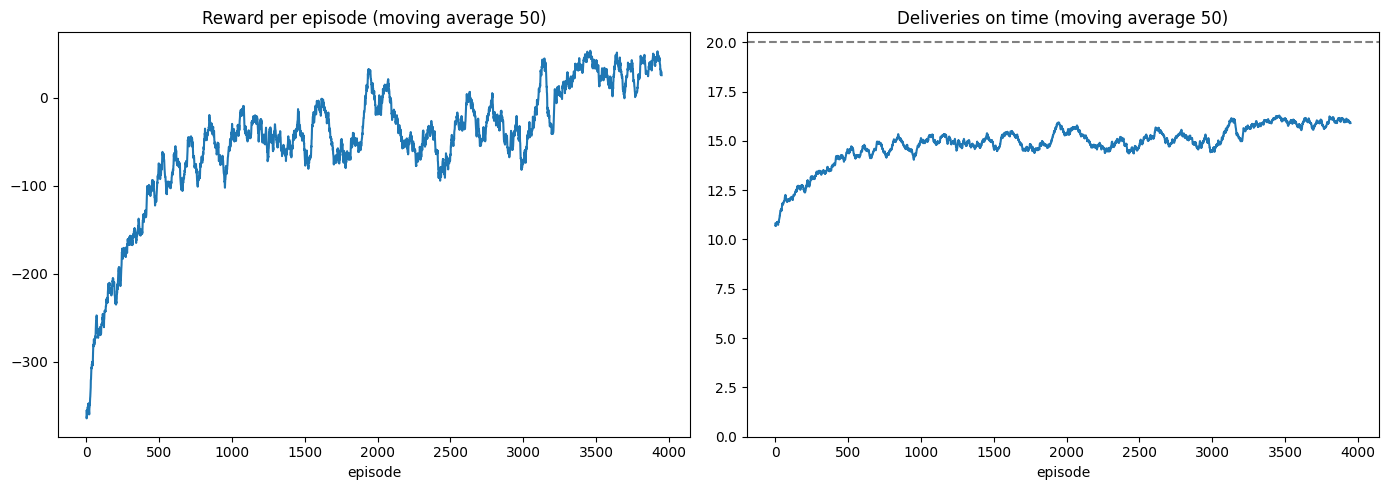

In [13]:
# Moving average: smooths the curve by averaging each window of w episodes
def moving_avg(x, w=50):
    return np.convolve(x, np.ones(w)/w, mode="valid")

# Create a figure with 2 side-by-side plots
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: total reward per episode
ax[0].plot(moving_avg(rewards_list))
ax[0].set_title("Reward per episode (moving average 50)")
ax[0].set_xlabel("episode")

# Right plot: deliveries on time per episode
ax[1].plot(moving_avg(deliveries_on_time_list))
ax[1].axhline(20, ls="--", c="gray")      # dashed line at the maximum (20 deliveries)
ax[1].set_title("Deliveries on time (moving average 50)")
ax[1].set_ylim(0, 20.5)
ax[1].set_xlabel("episode")

plt.tight_layout()
plt.show()

In [14]:
# This whole cell is used to COMPARE the trained Q-learning agent against simple rules
# that are commonly used to decide which delivery to do next (no learning involved).


# Runs full episodes where a fixed rule (policy) picks the deliveries instead of the Q-table.
# Returns the average deliveries on time and the average blocked deliveries per episode.
def test_policy(policy, num_operators=4, n_episodes=1000, seed=0):
    np.random.seed(seed); rd.seed(seed)
    env = logistics_center2(num_operators=num_operators)

    on_time_list, blocked_list = [], []
    for _ in range(n_episodes):
        env.reset()
        state, agent = env.state, env.agent
        on_time_count, blocked_count = 0, 0

        while state.status.any():
            operator = state.next_operator()
            pending = [i for i in range(env.num_deliveries) if state.status[i] == 1]

            delivery = policy(state, operator, pending)     # the policy picks the delivery
            on_time, blocked = agent.execute_delivery(delivery, operator)

            on_time_count += on_time
            blocked_count += blocked

        on_time_list.append(on_time_count)
        blocked_list.append(blocked_count)

    return np.mean(on_time_list), np.mean(blocked_list)


# For each pending delivery, simulates the route and returns (finish time, would wait?)
def route_info(state, operator, pending):
    info = {}
    for i in pending:
        finish, waited, _, _ = state.simulate_route(
            i, state.positions[operator], state.free_at[operator], state.busy_windows)
        info[i] = (finish, waited)
    return info


# Rule: pick the delivery with the earliest deadline
def earliest_deadline(state, operator, pending):
    return min(pending, key=lambda i: state.deadline[i])


# Rule: pick the delivery closest to being late (smallest deadline - finish time)
def least_slack(state, operator, pending):
    info = route_info(state, operator, pending)
    return min(pending, key=lambda i: state.deadline[i] - info[i][0])


# Rule: pick the delivery that finishes first (fastest route)
def earliest_finish(state, operator, pending):
    info = route_info(state, operator, pending)
    return min(pending, key=lambda i: info[i][0])


# Rule: pick the smallest ratio (deadline - now) / (route duration)
# It measures how much time is left compared to the work needed
def critical_ratio(state, operator, pending):
    info = route_info(state, operator, pending)
    start = state.free_at[operator]
    return min(pending, key=lambda i: (state.deadline[i] - start) / max(info[i][0] - start, 1))


# Rule: least slack, but deliveries that would not wait come first
def least_slack_no_wait(state, operator, pending):
    info = route_info(state, operator, pending)
    return min(pending, key=lambda i: (info[i][1], state.deadline[i] - info[i][0]))


# Rule: earliest deadline, but deliveries that would not wait come first
def earliest_deadline_no_wait(state, operator, pending):
    info = route_info(state, operator, pending)
    return min(pending, key=lambda i: (info[i][1], state.deadline[i]))


# --- Estimate of what is achievable: many random attempts per episode, keep the best ---

# Saves a copy of the changeable parts of the state
def snapshot(state):
    return (state.free_at.copy(), state.positions.copy(), state.status.copy(),
            [list(w) for w in state.busy_windows])


# Puts the state back exactly as it was in the snapshot
def restore(state, snap):
    state.free_at = snap[0].copy()
    state.positions = snap[1].copy()
    state.status = snap[2].copy()
    state.busy_windows = [list(w) for w in snap[3]]


# Least slack rule, but with probability `noise` it picks randomly among the 5 most urgent
def noisy_least_slack(state, operator, pending, noise):
    info = route_info(state, operator, pending)
    ranked = sorted(pending, key=lambda i: state.deadline[i] - info[i][0])
    if np.random.rand() < noise:
        return ranked[np.random.randint(min(5, len(ranked)))]
    return ranked[0]


# Plays one full episode with the noisy rule and returns the deliveries on time
def run_rollout(env, noise):
    state, agent = env.state, env.agent
    on_time_count = 0
    while state.status.any():
        operator = state.next_operator()
        pending = [i for i in range(env.num_deliveries) if state.status[i] == 1]
        delivery = noisy_least_slack(state, operator, pending, noise)
        on_time, _ = agent.execute_delivery(delivery, operator)
        on_time_count += on_time
    return on_time_count


# For each episode, replays the same scenario n_rollouts times and keeps the best score.
# Returns (average of the plain least slack run, average of the best runs).
def best_of_n(num_operators=4, n_episodes=50, n_rollouts=100, seed=0):
    np.random.seed(seed); rd.seed(seed)
    env = logistics_center2(num_operators=num_operators)
    first, best_list = [], []
    for _ in range(n_episodes):
        env.reset()
        snap = snapshot(env.state)
        best = 0
        for r in range(n_rollouts):
            restore(env.state, snap)
            noise = 0.0 if r == 0 else np.random.uniform(0.05, 0.6)
            score = run_rollout(env, noise)
            if r == 0:
                first.append(score)
            best = max(best, score)
        best_list.append(best)
    return np.mean(first), np.mean(best_list)


# Names of the rules to compare
policies = {
    "Earliest deadline": earliest_deadline,
    "Least slack": least_slack,
    "Earliest finish": earliest_finish,
    "Critical ratio": critical_ratio,
    "Least slack (no wait first)": least_slack_no_wait,
    "Earliest deadline (no wait first)": earliest_deadline_no_wait,
}

# Evaluate every rule with 1 and 4 operators
for nop in (1, 4):
    for name, policy in policies.items():
        a, b = test_policy(policy, nop, n_episodes=300)
        print(f"{name:34s} | {nop} op | on time {a:.2f}/20 | blocks/ep {b:.2f}")

# Estimate of what is achievable with random attempts
a, b = best_of_n(num_operators=4, n_episodes=50, n_rollouts=100)
print(f"Best of 100 random runs | 4 op | least slack {a:.2f}/20 | best found {b:.2f}/20")

Earliest deadline                  | 1 op | on time 20.00/20 | blocks/ep 0.00
Least slack                        | 1 op | on time 20.00/20 | blocks/ep 0.00
Earliest finish                    | 1 op | on time 11.27/20 | blocks/ep 0.00
Critical ratio                     | 1 op | on time 20.00/20 | blocks/ep 0.00
Least slack (no wait first)        | 1 op | on time 20.00/20 | blocks/ep 0.00
Earliest deadline (no wait first)  | 1 op | on time 20.00/20 | blocks/ep 0.00
Earliest deadline                  | 4 op | on time 12.28/20 | blocks/ep 10.82
Least slack                        | 4 op | on time 10.15/20 | blocks/ep 11.06
Earliest finish                    | 4 op | on time 12.26/20 | blocks/ep 8.24
Critical ratio                     | 4 op | on time 9.86/20 | blocks/ep 11.12
Least slack (no wait first)        | 4 op | on time 10.78/20 | blocks/ep 4.63
Earliest deadline (no wait first)  | 4 op | on time 11.57/20 | blocks/ep 4.57
Best of 100 random runs | 4 op | least slack 12.04/20 | best f

In [15]:
# final model evaluation
env2.evaluate(1000)

16.231

In [16]:

import time
import copy

def build_scaled_warehouse(size):
    """
    Builds a larger warehouse following the same layout as the original 10x10 environment.
    0 = empty cell, 1 = loading dock, 2 = SKU shelf.
    For size=10, the original warehouse layout is preserved.
    """
    warehouse = np.zeros((size, size))

    # Create L-shaped loading docks along the top row and left column
    for i in range(size // 2):
        warehouse[i, 0] = 1
        warehouse[0, i + 1] = 1

    # Create shelf rows at regular intervals
    num_shelf_rows = (size - 2) // 2
    for j in range(2, 2 * num_shelf_rows + 1, 2):
        warehouse[j, 2:size - 2] = 2

    return warehouse, num_shelf_rows


def make_fast_distance(warehouse):
    """
    Calculates distances in constant time for the warehouse layout.
    It follows the same rules as BFS: shelves cannot be crossed,
    but the destination can be a shelf.
    """
    is_shelf = (warehouse == 2)
    n_rows, n_cols = warehouse.shape

    shelf_rows = [r for r in range(n_rows) if is_shelf[r].any()]
    lane_cols = [c for c in range(n_cols) if not is_shelf[:, c].any()]

    shelf_count = np.cumsum([1 if r in shelf_rows else 0 for r in range(n_rows)])
    middle = n_cols / 2
    cache = {}

    def free_neighbors(cell):
        # Get adjacent cells that are not shelves
        r, c = cell
        out = []
        for nr, nc in ((r - 1, c), (r + 1, c), (r, c - 1), (r, c + 1)):
            if 0 <= nr < n_rows and 0 <= nc < n_cols and not is_shelf[nr, nc]:
                out.append((nr, nc))
        return out

    def dist_free(a, b):
        # Calculate the distance between two non-shelf cells
        (r1, c1), (r2, c2) = a, b

        if r1 == r2:
            if not is_shelf[r1].any():
                return abs(c1 - c2)

            if (c1 < middle) == (c2 < middle):
                return abs(c1 - c2)

            return abs(c1 - c2) + 2

        lo, hi = min(r1, r2), max(r1, r2)
        shelves_between = shelf_count[hi - 1] - shelf_count[lo]

        if shelves_between == 0:
            return (hi - lo) + abs(c1 - c2)

        # If shelves block the path, use one of the side lanes
        return (hi - lo) + min(
            abs(c1 - L) + abs(L - c2) for L in lane_cols
        )

    def distance(start, target):
        # Calculate and cache the shortest distance between two cells
        a = (int(start[0]), int(start[1]))
        b = (int(target[0]), int(target[1]))
        key = (a, b)

        if key in cache:
            return cache[key]

        if a == b:
            d = 0

        elif not is_shelf[a] and not is_shelf[b]:
            d = dist_free(a, b)

        elif is_shelf[a] and is_shelf[b]:
            if a[0] == b[0] and abs(a[1] - b[1]) == 1:
                d = 1
            else:
                d = 2 + min(
                    dist_free(na, nb)
                    for na in free_neighbors(a)
                    for nb in free_neighbors(b)
                )

        else:
            free_cell, shelf_cell = (b, a) if is_shelf[a] else (a, b)
            d = 1 + min(
                dist_free(free_cell, nb)
                for nb in free_neighbors(shelf_cell)
            )

        cache[key] = d
        return d

    return distance


def make_scaled_env(trained_env, size, num_operators=None, num_deliveries=None):
    """
    Creates a larger warehouse environment using a COPY of the trained Q-table.
    The original trained environment remains unchanged.
    """
    warehouse, num_shelf_rows = build_scaled_warehouse(size)

    env = logistics_center2(
        num_docks=size,
        num_SKU=num_shelf_rows,
        num_deliveries=num_deliveries or trained_env.num_deliveries,
        top_k=trained_env.top_k,
        num_operators=num_operators or trained_env.num_operators
    )

    env.warehouse = warehouse
    env.num_SKU = num_shelf_rows

    # Replace BFS with the optimized distance calculation
    env.shortest_path_distance = make_fast_distance(warehouse)

    # Preserve the original environment parameters and trained Q-table
    env.block_penalty = trained_env.block_penalty
    env.my_table = copy.deepcopy(trained_env.my_table)

    return env


def run_policy(env, policy, n_episodes, seed, slack_bins=None):
    """
    Evaluates a policy over multiple episodes without further training.

    policy = None: uses the trained Q-table greedily (no exploration).
    policy = function: uses a predefined delivery selection strategy.
    """
    np.random.seed(seed)
    rd.seed(seed)

    table = env.my_table

    on_time_total = blocked_total = decisions = unseen = 0
    start = time.time()

    for _ in range(n_episodes):
        env.reset()
        state, agent = env.state, env.agent

        # Optionally adjust deadline slack ranges for larger warehouses
        if slack_bins is not None:
            state.SLACK_BINS = slack_bins

        operator = state.next_operator()

        while True:
            if policy is None:
                # Select an action using the trained Q-table
                cands, obs = state.observation(operator)

                decisions += 1
                unseen += obs not in table.q_table

                action = table.choose_action(
                    obs, len(cands), greedy=True
                )
                delivery = agent.pick_delivery(action, cands)

            else:
                # Select a delivery using the predefined policy
                pending = [
                    i for i in range(env.num_deliveries)
                    if state.status[i] == 1
                ]
                delivery = policy(state, operator, pending)

            # Execute the selected delivery and collect performance metrics
            on_time, blocked = agent.execute_delivery(delivery, operator)

            on_time_total += on_time
            blocked_total += blocked

            if not state.status.any():
                break

            operator = state.next_operator()

    # Return the average performance metrics across all episodes
    n = env.num_deliveries

    return {
        "on_time": on_time_total / n_episodes,
        "percentage": 100 * on_time_total / (n_episodes * n),
        "blocked": blocked_total / n_episodes,
        "unseen_states": 100 * unseen / decisions if decisions else 0.0,
        "seconds_per_episode": (time.time() - start) / n_episodes
    }


def earliest_deadline_policy(state, operator, pending):
    """Selects the pending delivery with the earliest deadline."""
    return min(pending, key=lambda i: state.deadline[i])


def test_larger_warehouses(
    trained_env,
    sizes=(10, 30, 60, 100, 150),
    n_episodes=100,
    seed=0,
    num_operators=None,
    num_deliveries=None
):
    """
    Tests the scalability of the trained model across different warehouse sizes.

    Compares the trained Q-learning model with original and scaled
    slack ranges, as well as a simple earliest-deadline baseline.
    """
    base_bins = list(State2.SLACK_BINS)

    # Print the results table header
    print(
        f"{'Size':>8} | {'Policy':<28} | {'On time':>9} | "
        f"{'%':>5} | {'Blocked/ep':>10} | "
        f"{'Unseen states':>13} | {'s/ep':>5}"
    )

    for size in sizes:
        # Create a warehouse with the current dimensions
        env = make_scaled_env(
            trained_env, size, num_operators, num_deliveries
        )

        # Scale deadline slack ranges proportionally to warehouse size
        scaled_bins = [b * size / 10 for b in base_bins]

        # Define the policies to be evaluated
        runs = [
            ("Q-learning (original bins)", None, None),
            ("Q-learning (scaled bins)", None, scaled_bins),
            ("Earliest deadline (baseline)", earliest_deadline_policy, None),
        ]

        # Evaluate each policy under the same random seed
        for name, policy, bins in runs:
            r = run_policy(env, policy, n_episodes, seed, bins)

            print(
                f"{size:>3}x{size:<4} | {name:<28} | "
                f"{r['on_time']:>6.2f}/{env.num_deliveries} | "
                f"{r['percentage']:>4.0f}% | "
                f"{r['blocked']:>10.2f} | "
                f"{r['unseen_states']:>12.1f}% | "
                f"{r['seconds_per_episode']:>5.2f}"
            )

        print("-" * 100)


# ---- Run scalability tests ----
test_larger_warehouses(
    env2,
    sizes=(300, 400, 500),
    n_episodes=100,
    num_operators=50,
    num_deliveries=250
)


    Size | Policy                       |   On time |     % | Blocked/ep | Unseen states |  s/ep
300x300  | Q-learning (original bins)   | 208.95/250 |   84% |       3.84 |          0.7% |  2.76
300x300  | Q-learning (scaled bins)     | 212.57/250 |   85% |       4.16 |          0.9% |  1.67
300x300  | Earliest deadline (baseline) | 144.55/250 |   58% |      75.09 |          0.0% |  0.32
----------------------------------------------------------------------------------------------------
400x400  | Q-learning (original bins)   | 205.43/250 |   82% |       2.45 |          0.6% |  3.46
400x400  | Q-learning (scaled bins)     | 209.66/250 |   84% |       2.48 |          0.8% |  2.41
400x400  | Earliest deadline (baseline) | 139.40/250 |   56% |      55.70 |          0.0% |  0.47
----------------------------------------------------------------------------------------------------
500x500  | Q-learning (original bins)   | 199.42/250 |   80% |       1.77 |          0.6% |  2.95
500x500  | Q-le

    Size | Policy                       |   On time |     % | Blocked/ep | Unseen states |  s/ep
300x300  | Q-learning (original bins)   | 208.95/250 |   84% |       3.84 |          0.7% |  2.18
300x300  | Q-learning (scaled bins)     | 212.57/250 |   85% |       4.16 |          0.9% |  2.36
300x300  | Earliest deadline (baseline) | 144.55/250 |   58% |      75.09 |          0.0% |  0.31
----------------------------------------------------------------------------------------------------
400x400  | Q-learning (original bins)   | 205.43/250 |   82% |       2.45 |          0.6% |  3.01
400x400  | Q-learning (scaled bins)     | 209.66/250 |   84% |       2.48 |          0.8% |  1.83
400x400  | Earliest deadline (baseline) | 139.40/250 |   56% |      55.70 |          0.0% |  0.41
----------------------------------------------------------------------------------------------------
500x500  | Q-learning (original bins)   | 199.42/250 |   80% |       1.77 |          0.6% |  3.68
500x500  | Q-le

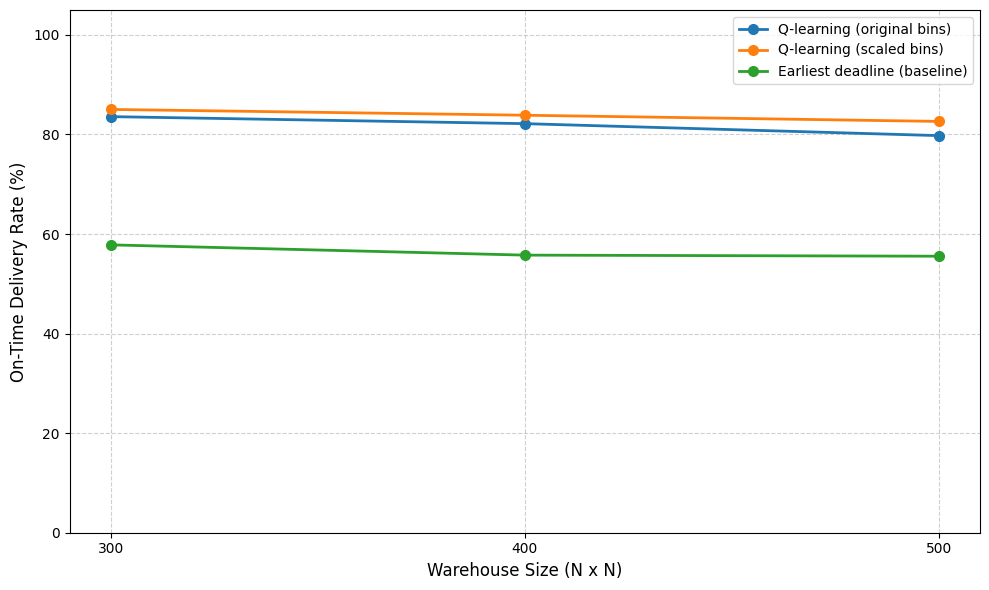

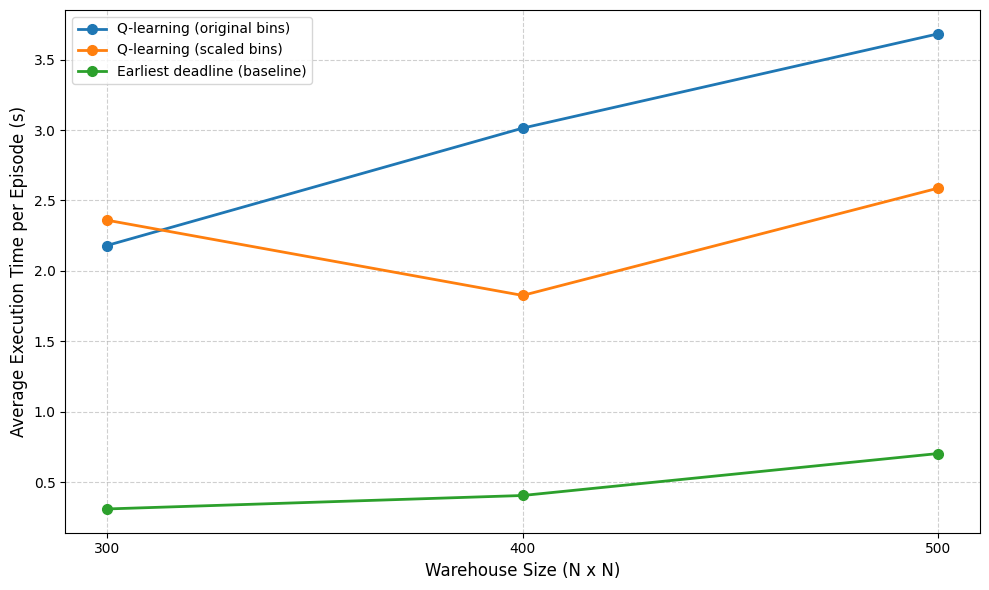

In [20]:

import matplotlib.pyplot as plt
import numpy as np

def test_larger_warehouses(
    trained_env,
    sizes=(10, 30, 60, 100, 150),
    n_episodes=100,
    seed=0,
    num_operators=None,
    num_deliveries=None
):
    """
    Evaluates the scalability of the trained model across different
    warehouse sizes and generates performance and execution time plots.
    """

    base_bins = list(State2.SLACK_BINS)

    # Store results for each warehouse size and policy
    results = {
        "Q-learning (original bins)": {
            "percentage": [],
            "time": []
        },
        "Q-learning (scaled bins)": {
            "percentage": [],
            "time": []
        },
        "Earliest deadline (baseline)": {
            "percentage": [],
            "time": []
        }
    }

    print(
        f"{'Size':>8} | {'Policy':<28} | {'On time':>9} | "
        f"{'%':>5} | {'Blocked/ep':>10} | "
        f"{'Unseen states':>13} | {'s/ep':>5}"
    )

    for size in sizes:

        # Create a warehouse with the current dimensions
        env = make_scaled_env(
            trained_env,
            size,
            num_operators,
            num_deliveries
        )

        # Scale deadline slack ranges according to warehouse size
        scaled_bins = [b * size / 10 for b in base_bins]

        # Define the policies to be evaluated
        runs = [
            ("Q-learning (original bins)", None, None),
            ("Q-learning (scaled bins)", None, scaled_bins),
            ("Earliest deadline (baseline)",
             earliest_deadline_policy, None)
        ]

        for name, policy, bins in runs:

            # Run the evaluation without further training
            r = run_policy(
                env,
                policy,
                n_episodes,
                seed,
                bins
            )

            # Store performance and execution time
            # Store performance and execution time
            results[name]["percentage"].append(r["percentage"])
            results[name]["time"].append(r["seconds_per_episode"])

            print(
                f"{size:>3}x{size:<4} | {name:<28} | "
                f"{r['on_time']:>6.2f}/{env.num_deliveries} | "
                f"{r['percentage']:>4.0f}% | "
                f"{r['blocked']:>10.2f} | "
                f"{r['unseen_states']:>12.1f}% | "
                f"{r['seconds_per_episode']:>5.2f}"
            )

        print("-" * 100)

    # Convert warehouse sizes into a NumPy array
    sizes = np.array(sizes)

    # ---------------------------------------------------------
    # GRAPH 1: DELIVERY PERFORMANCE VS. WAREHOUSE SIZE
    # ---------------------------------------------------------

    plt.figure(figsize=(10, 6))

    for name, data in results.items():
        plt.plot(
            sizes,
            data["percentage"],
            marker='o',
            linewidth=2,
            markersize=7,
            label=name
        )

    plt.xlabel("Warehouse Size (N x N)", fontsize=12)
    plt.ylabel("On-Time Delivery Rate (%)", fontsize=12)
    plt.xticks(sizes)
    plt.ylim(0, 105)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.tight_layout()

    plt.savefig("scalability_performance.png", dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # GRAPH 2: EXECUTION TIME VS. WAREHOUSE SIZE
    # ---------------------------------------------------------

    plt.figure(figsize=(10, 6))

    for name, data in results.items():
        plt.plot(
            sizes,
            data["time"],
            marker='o',
            linewidth=2,
            markersize=7,
            label=name
        )

    plt.xlabel("Warehouse Size (N x N)", fontsize=12)
    plt.ylabel("Average Execution Time per Episode (s)", fontsize=12)
    plt.xticks(sizes)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.tight_layout()

    plt.savefig("scalability_execution_time.png", dpi=300)
    plt.show()

    return results


# ---- Run scalability experiments ----

results = test_larger_warehouses(
    env2,
    sizes=(300, 400, 500),
    n_episodes=100,
    num_operators=50,
    num_deliveries=250
)
